# 05 · Feature-family ablation tournament

Chronological validation only: expanding window from 2016, evaluation years **2022, 2023, 2024**.
The locked 2025 test year is never loaded (`load_development_panel`, and `fold_data` refuses any fold after 2024).

**Models (fixed configurations).** Poisson GLM (ridge strength chosen *inside every fit* by a chronological hold-out of
the last training year) and LightGBM with the Poisson objective (7 leaves, 400 trees, learning rate 0.03; chosen on an inner
split of 2016–2021, `reports/features/model_config.json`). **No search was run on 2022–2024.**
Each model is scored with its conditional **mean** and with the **Poisson median** of the same fitted rate; the median is the
MAE-optimal point forecast under the model, so it is the headline.

**Convention.** `A_end_of_week` (as in Stage 1) unless stated. B and C are in notebook 06.

**Reading the numbers.** There are three validation seasons. Differences below **0.1 MAE** are flagged *inconclusive*
unless they are also consistent in sign across folds, horizons and both models.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
np.random.seed(2026)
import matplotlib.pyplot as plt
from cycler import cycler
from dengueshield.data import load_development_panel
from dengueshield.evaluation.folds import fold_data, dev_folds
from dengueshield.evaluation import ablation as ab

OUT = ROOT / "reports/features"; FIG = OUT / "figures"; TAB = OUT / "tables"
for d in (FIG, TAB): d.mkdir(parents=True, exist_ok=True)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, SURF, MUTED = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb", "#b9b8b2"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": INK2,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "axes.prop_cycle": cycler(color=SERIES), "savefig.dpi": 130, "savefig.bbox": "tight"})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png"); plt.show(); plt.close(fig)

panel = load_development_panel(); assert panel.date.dt.year.max() == 2024
lib = ab.library(fold_data(panel, "A_end_of_week", dev_folds()[0], 3).manifest)
cfgs, fw = ab.configs(lib), ab.forward_configs(lib)
print(len(cfgs), "family/ablation configs;", len(fw), "forward-step configs; combined library =", len(lib["all"]), "features")

39 family/ablation configs; 10 forward-step configs; combined library = 196 features


## 1. Run (or load cached) tournament

In [2]:
import time
t0 = time.time()
resA, _ = ab.tournament(panel, cfgs, log=lambda *a: None)
resF, _ = ab.tournament(panel, fw, log=lambda *a: None)
resE = pd.concat([ab.tournament(panel, {f"F3_est_{m}": cfgs["F3_aligned_rain"]}, rain_est=m, log=lambda *a: None)[0] for m in ("zero", "clim")], ignore_index=True)
res = pd.concat([resA, resF, resE], ignore_index=True)
res.to_csv(OUT / "ablation_raw_convA.csv", index=False)
print(f"{len(res):,} result rows; {time.time() - t0:.0f}s (cached runs are instant)")
lb = ab.leaderboard(res, "median"); lb_mean = ab.leaderboard(res, "mean")
lb.to_csv(OUT / "leaderboard_convA_median.csv", index=False); lb_mean.to_csv(OUT / "leaderboard_convA_mean.csv", index=False)

1,836 result rows; 0s (cached runs are instant)


## 2. Full leaderboard (Poisson-median forecasts, mean over 3 validation folds)

In [3]:
cols = ["config", "model", "mae_h2", "mae_h3", "mae_h4", "mae_avg", "fold_sd", "rmse", "high_mae", "high_bias", "under_rate", "recall", "fit_s", "predict_s", "n_features"]
board = lb.sort_values("mae_avg")[cols]
board.round(3).to_csv(OUT / "leaderboard_full.csv", index=False)
pd.set_option("display.max_rows", 200)
board[board.model == "glm"].round(3).reset_index(drop=True)

horizon,config,model,mae_h2,mae_h3,mae_h4,mae_avg,fold_sd,rmse,high_mae,high_bias,under_rate,recall,fit_s,predict_s,n_features
0,F3plus_zero_infl,glm,1.069,1.128,1.434,1.210,0.158,2.391,4.128,-2.905,0.228,0.617,0.531,0.000,43.0
1,F3_est_clim,glm,1.075,1.136,1.432,1.214,0.163,2.399,4.199,-2.977,0.229,0.604,0.367,0.000,38.0
2,F3_no_uncertainty_flags,glm,1.069,1.139,1.440,1.216,0.162,2.391,4.148,-3.000,0.226,0.610,0.475,0.000,32.0
3,F3_aligned_rain,glm,1.075,1.137,1.437,1.216,0.167,2.400,4.197,-3.004,0.227,0.607,0.382,0.000,38.0
4,F3plus_vuln,glm,1.076,1.134,1.443,1.218,0.170,2.399,4.189,-2.914,0.228,0.604,0.676,0.000,53.0
5,F3plus_breeding,glm,1.053,1.151,1.457,1.220,0.164,2.404,4.212,-2.900,0.226,0.615,0.489,0.000,43.0
6,F3plus_climate_int,glm,1.062,1.149,1.457,1.223,0.180,2.422,4.262,-3.044,0.229,0.607,0.473,0.000,44.0
7,F3_est_zero,glm,1.075,1.191,1.438,1.235,0.174,2.463,4.305,-3.238,0.231,0.595,0.371,0.000,38.0
8,F3plus_hist,glm,1.077,1.140,1.494,1.237,0.192,2.432,4.335,-3.296,0.233,0.570,0.478,0.000,46.0
9,inc_vuln,glm,1.094,1.154,1.478,1.242,0.199,2.444,4.433,-3.450,0.242,0.557,0.348,0.000,33.0


In [4]:
board[board.model == "lgbm"].round(3).reset_index(drop=True)

horizon,config,model,mae_h2,mae_h3,mae_h4,mae_avg,fold_sd,rmse,high_mae,high_bias,under_rate,recall,fit_s,predict_s,n_features
0,F3plus_humidity,lgbm,1.096,1.165,1.470,1.244,0.208,2.522,4.298,-3.320,0.224,0.587,0.484,0.005,53.0
1,F3_est_clim,lgbm,1.102,1.163,1.468,1.244,0.210,2.512,4.310,-3.276,0.224,0.578,0.428,0.005,38.0
2,F3plus_breeding,lgbm,1.088,1.167,1.479,1.245,0.191,2.481,4.198,-3.103,0.218,0.616,0.450,0.005,43.0
3,F3plus_case,lgbm,1.107,1.167,1.469,1.248,0.210,2.509,4.280,-3.291,0.224,0.596,0.510,0.005,75.0
4,F3plus_vuln,lgbm,1.086,1.162,1.496,1.248,0.195,2.499,4.223,-3.136,0.223,0.601,0.467,0.005,53.0
5,F3_aligned_rain,lgbm,1.102,1.167,1.476,1.248,0.209,2.512,4.274,-3.237,0.222,0.592,0.438,0.005,38.0
6,F3plus_zero_infl,lgbm,1.105,1.172,1.479,1.252,0.206,2.524,4.306,-3.284,0.223,0.586,0.469,0.006,43.0
7,rm_rain_lag,lgbm,1.081,1.163,1.515,1.253,0.184,2.518,4.357,-3.461,0.229,0.589,0.906,0.007,185.0
8,F3plus_climate_int,lgbm,1.087,1.178,1.496,1.254,0.200,2.523,4.330,-3.388,0.224,0.593,0.462,0.005,44.0
9,F3_est_zero,lgbm,1.102,1.184,1.475,1.254,0.226,2.528,4.307,-3.299,0.221,0.585,0.437,0.005,38.0


## 3. The requested feature families F0–F7

In [5]:
fam_names = ["F0_stage1_features", "F1_calendar_static", "F2_rain_memory", "F3_aligned_rain", "F4_climate_interactions", "F5_case_history", "F6_hist_seasonal", "F7_combined"]
F = lb[lb.config.isin(fam_names)].set_index(["config", "model"]).loc[[(c, m) for c in fam_names for m in ("glm", "lgbm")]]
F.round(3)[["mae_h2", "mae_h3", "mae_h4", "mae_avg", "fold_sd", "mae_val_2022", "mae_val_2023", "mae_val_2024", "rmse", "high_mae", "high_bias", "recall", "n_features"]]

horizon                        mae_h2  mae_h3  mae_h4  mae_avg  fold_sd  mae_val_2022  mae_val_2023  mae_val_2024   rmse  high_mae  high_bias  recall  \
config                  model                                                                                                                           
F0_stage1_features      glm     1.103   1.229   1.546    1.293    0.157         1.435         1.320         1.124  2.581     4.679     -3.008   0.549   
                        lgbm    1.147   1.195   1.459    1.267    0.236         1.487         1.296         1.018  2.549     4.341     -3.512   0.600   
F1_calendar_static      glm     1.436   1.459   1.519    1.471    0.284         1.640         1.631         1.143  2.955     5.104     -4.637   0.505   
                        lgbm    1.488   1.519   1.550    1.519    0.283         1.646         1.717         1.194  3.074     4.975     -4.228   0.574   
F2_rain_memory          glm     1.127   1.202   1.543    1.291    0.144         1.426         1.307         1.139  2.596     4.704     -3.306   0.555   
                        lgbm    1.138   1.195   1.524    1.286    0.212         1.466         1.340         1.052  2.598     4.727     -4.051   0.520   
F3_aligned_rain         glm     1.075   1.137   1.437    1.216    0.167         1.363         1.253         1.034  2.400     4.197     -3.004   0.607   
                        lgbm    1.102   1.167   1.476    1.248    0.209         1.475         1.207         1.063  2.512     4.274     -3.237   0.592   
F4_climate_interactions glm     1.071   1.159   1.546    1.259    0.215         1.450         1.300         1.026  2.486     4.393     -3.238   0.579   
                        lgbm    1.100   1.209   1.471    1.260    0.242         1.445         1.349         0.986  2.537     4.340     -3.621   0.589   
F5_case_history         glm     1.461   1.477   1.534    1.491    0.298         1.641         1.684         1.147  2.976     5.017     -4.380   0.534   
                        lgbm    1.499   1.507   1.547    1.518    0.295         1.668         1.707         1.178  3.050     5.010     -4.185   0.572   
F6_hist_seasonal        glm     1.286   1.409   1.536    1.410    0.227         1.525         1.557         1.149  2.814     4.775     -3.744   0.565   
                        lgbm    1.338   1.425   1.545    1.436    0.288         1.606         1.598         1.103  2.888     4.974     -4.163   0.547   
F7_combined             glm     1.082   1.201   1.543    1.275    0.184         1.449         1.293         1.083  2.523     4.624     -3.227   0.547   
                        lgbm    1.088   1.187   1.537    1.271    0.200         1.420         1.348         1.043  2.561     4.486     -3.558   0.578   

horizon                        n_features  
config                  model              
F0_stage1_features      glm          16.0  
                        lgbm         16.0  
F1_calendar_static      glm          18.0  
                        lgbm         18.0  
F2_rain_memory          glm          59.0  
                        lgbm         59.0  
F3_aligned_rain         glm          38.0  
                        lgbm         38.0  
F4_climate_interactions glm          85.0  
                        lgbm         85.0  
F5_case_history         glm          55.0  
                        lgbm         55.0  
F6_hist_seasonal        glm          26.0  
                        lgbm         26.0  
F7_combined             glm         196.0  
                        lgbm        196.0

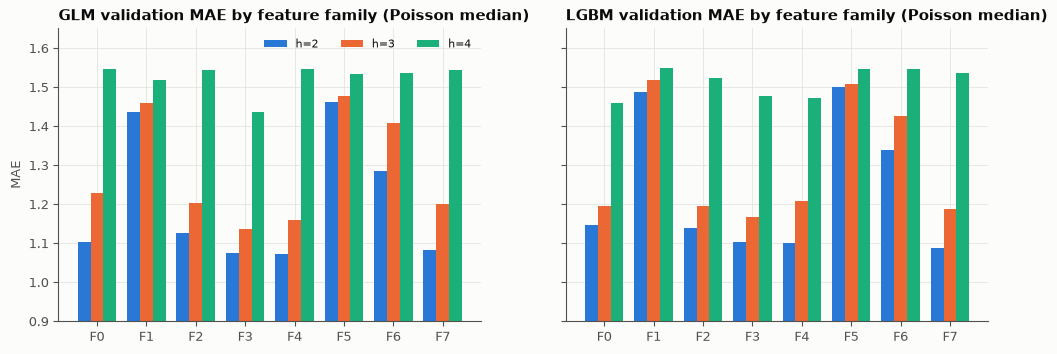

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, model in zip(ax, ("glm", "lgbm")):
    d = F.xs(model, level="model").loc[fam_names]
    x = np.arange(len(fam_names)); w = 0.26
    for i, h in enumerate((2, 3, 4)):
        a.bar(x + (i - 1) * w, d[f"mae_h{h}"], w, color=SERIES[i], label=f"h={h}")
    a.set_xticks(x); a.set_xticklabels([n.split("_")[0] for n in fam_names]); a.set_title(f"{model.upper()} validation MAE by feature family (Poisson median)")
    a.set_ylim(0.9, 1.65)
ax[0].set_ylabel("MAE"); ax[0].legend(ncol=3, fontsize=8)
save(fig, "06_family_mae_by_horizon")

### Incremental (over F1) and removal (from F7) ablations

* **Incremental gain** = MAE(F1) − MAE(F1 + family): positive means the family helps *on top of calendar and static attributes*.
* **Removal loss** = MAE(F7 − family) − MAE(F7): positive means removing the family hurts.

In [7]:
base = lb.set_index(["config", "model"]).mae_avg
rows = []
for fam in ab.FAMILIES:
    for model in ("glm", "lgbm"):
        inc = base.get((f"inc_{fam}", model), np.nan)
        rows.append({"family": fam, "model": model, "incremental_gain_over_F1": base[("F1_calendar_static", model)] - inc,
                     "removal_loss_from_F7": base[(f"rm_{fam}", model)] - base[("F7_combined", model)]})
abl = pd.DataFrame(rows)
# F2/F3/F4/F5/F6 incremental gains are the bundled configs
bundle = {"rain_lag+rain_roll (F2)": "F2_rain_memory", "rain_align (F3)": "F3_aligned_rain", "F4 bundle": "F4_climate_interactions", "case (F5)": "F5_case_history", "hist (F6)": "F6_hist_seasonal"}
bund = pd.DataFrame([{"bundle": k, "model": m, "gain_over_F1": base[("F1_calendar_static", m)] - base[(v, m)]} for k, v in bundle.items() for m in ("glm", "lgbm")])
abl.round(4).to_csv(TAB / "ablation_family_deltas.csv", index=False); bund.round(4).to_csv(TAB / "ablation_bundle_gains.csv", index=False)
display(bund.pivot(index="bundle", columns="model", values="gain_over_F1").round(3))
abl.pivot(index="family", columns="model", values=["incremental_gain_over_F1", "removal_loss_from_F7"]).round(3)

model,glm,lgbm
bundle,,
F4 bundle,0.213,0.259
case (F5),-0.019,0.001
hist (F6),0.061,0.083
rain_align (F3),0.255,0.271
rain_lag+rain_roll (F2),0.181,0.233


incremental_gain_over_F1        removal_loss_from_F7       
model                            glm   lgbm                  glm   lgbm
family                                                                 
breeding                       0.163  0.186               -0.005 -0.004
calendar                         NaN    NaN                0.036 -0.009
case                             NaN    NaN               -0.012 -0.004
climate_int                    0.188  0.204               -0.000 -0.002
hist                             NaN    NaN               -0.001 -0.007
humidity                      -0.060 -0.003                0.006  0.001
rain_align                       NaN    NaN                0.010 -0.000
rain_lag                       0.216  0.225                0.015 -0.018
rain_roll                      0.164  0.202               -0.000 -0.016
static                           NaN    NaN               -0.002  0.000
temp                          -0.029 -0.007                0.015  0.001
vuln                           0.229  0.241               -0.001 -0.001
zero_infl                     -0.011  0.010               -0.002 -0.001

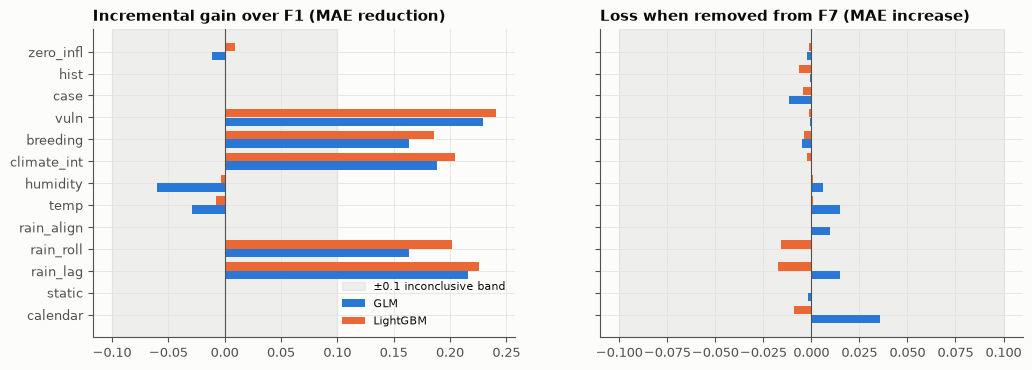

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
p = abl.pivot(index="family", columns="model", values="incremental_gain_over_F1").reindex(ab.FAMILIES)
q = abl.pivot(index="family", columns="model", values="removal_loss_from_F7").reindex(ab.FAMILIES)
y = np.arange(len(p))
for a, (tab, title) in zip(ax, [(p, "Incremental gain over F1 (MAE reduction)"), (q, "Loss when removed from F7 (MAE increase)")]):
    a.axvspan(-0.1, 0.1, color=MUTED, alpha=0.2, label="±0.1 inconclusive band", zorder=0)
    a.barh(y - 0.2, tab.glm, 0.38, color=SERIES[0], label="GLM", zorder=3); a.barh(y + 0.2, tab.lgbm, 0.38, color=SERIES[1], label="LightGBM", zorder=3)
    a.axvline(0, color=INK2, lw=0.8, zorder=4)
    a.set_yticks(y); a.set_yticklabels(ab.FAMILIES); a.set_title(title); a.invert_yaxis()
ax[0].legend(fontsize=8, loc="lower right")
save(fig, "07_incremental_and_removal")

## 4. Family-level forward step on top of the best single family (F3)

Decision rule fixed **before** looking at these numbers: keep a family if, for **both** models, the mean MAE (3 horizons × 3 folds)
improves by at least 0.01 **and** improves in at least 2 of the 3 validation folds. Ten candidate additions → ten comparisons on the
same validation folds, so the false-positive risk is real; the rule requires agreement between two different model types.

In [9]:
fwd = ab.decision_rule(res, "F3_aligned_rain", list(fw))
fwd.round(4).to_csv(OUT / "forward_step_decision.csv", index=False)
fl = lb[lb.config.isin(fw)].set_index("config").loc[list(fw)]
display(fwd.round(3))

,config,glm_gain,glm_folds_improved,lgbm_gain,lgbm_folds_improved,keep
0,F3plus_rain_lag,-0.037,0,-0.009,1,False
1,F3plus_rain_roll,-0.122,0,-0.020,1,False
2,F3plus_temp,-0.027,0,-0.017,1,False
3,F3plus_humidity,-0.026,1,0.005,3,False
4,F3plus_climate_int,-0.006,1,-0.005,2,False
5,F3plus_breeding,-0.004,1,0.004,2,False
6,F3plus_vuln,-0.001,1,0.000,2,False
7,F3plus_case,-0.042,0,0.001,2,False
8,F3plus_hist,-0.021,0,-0.023,1,False
9,F3plus_zero_infl,0.006,2,-0.004,0,False


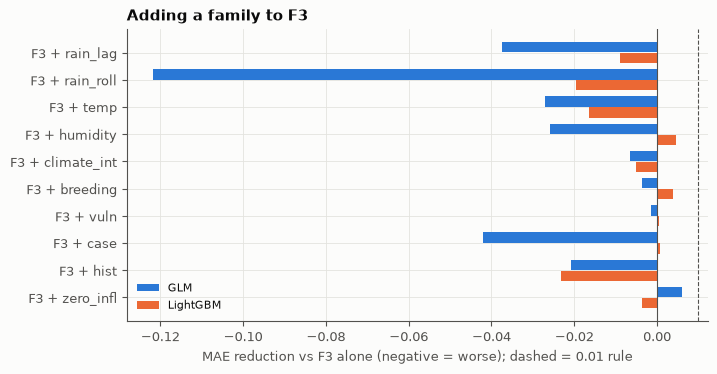

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(fwd))
ax.barh(y - 0.2, fwd.glm_gain, 0.38, color=SERIES[0], label="GLM"); ax.barh(y + 0.2, fwd.lgbm_gain, 0.38, color=SERIES[1], label="LightGBM")
ax.axvline(0, color=INK2, lw=0.8); ax.axvline(0.01, color=INK2, lw=0.8, ls="--")
ax.set_yticks(y); ax.set_yticklabels([c.replace("F3plus_", "F3 + ") for c in fwd.config]); ax.invert_yaxis(); ax.legend(fontsize=8)
ax.set_xlabel("MAE reduction vs F3 alone (negative = worse); dashed = 0.01 rule"); ax.set_title("Adding a family to F3")
save(fig, "08_forward_step")

## 5. Handling rainfall that has not happened yet (horizons 3–4)

In [11]:
strat = res[res.config.isin(["F3_aligned_rain", "F3_est_clim", "F3_est_zero", "F2_rain_memory"]) & (res.kind == "median")]
strat = strat.assign(strategy=strat.config.map({"F3_aligned_rain": "regime-adjusted climatology", "F3_est_clim": "plain climatology",
                                              "F3_est_zero": "zero future rain", "F2_rain_memory": "observed history only (F2)"}))
t = strat.groupby(["strategy", "model", "horizon"]).all_mae.mean().unstack("horizon").round(3)
t["avg"] = t.mean(axis=1).round(3); t.to_csv(TAB / "rain_projection_strategies.csv"); t

horizon                                2      3      4    avg
strategy                    model                            
observed history only (F2)  glm    1.127  1.202  1.543  1.291
                            lgbm   1.138  1.195  1.524  1.286
plain climatology           glm    1.075  1.136  1.432  1.214
                            lgbm   1.102  1.163  1.468  1.244
regime-adjusted climatology glm    1.075  1.137  1.437  1.216
                            lgbm   1.102  1.167  1.476  1.248
zero future rain            glm    1.075  1.191  1.438  1.235
                            lgbm   1.102  1.184  1.475  1.254

**Estimate quality versus truth** (reporting only) is in `tables/rain_projection_accuracy_h4.csv` from notebook 04.

## 6. Mean versus median forecast

In [12]:
mm = res[res.config.isin(fam_names)].groupby(["config", "model", "kind"]).all_mae.mean().unstack("kind")
mm["median_gain"] = mm["mean"] - mm["median"]; mm.round(3).to_csv(TAB / "mean_vs_median_mae.csv")
print("average MAE gain from the Poisson-median forecast:", mm.median_gain.mean().round(3), "(min", mm.median_gain.min().round(3), "max", mm.median_gain.max().round(3), ")")
rm_ = res[res.config.isin(fam_names)].groupby(["model", "kind"])[["all_rmse", "all_bias", "high_bias", "all_poisson_dev"]].mean().round(3); rm_

average MAE gain from the Poisson-median forecast: 0.049 (min 0.032 max 0.087 )


all_rmse  all_bias  high_bias  all_poisson_dev
model kind                                                  
glm   mean       2.645    -0.126     -3.401            1.322
      median     2.666    -0.286     -3.568            1.693
lgbm  mean       2.703    -0.142     -3.652            1.290
      median     2.721    -0.253     -3.820            1.609

## 7. Temperature redundancy and breeding-index components

In [13]:
tt = lb.set_index(["config", "model"]).mae_avg.unstack("model")
temp = tt.loc[["F1_calendar_static", "inc_temp", "inc_temp_no_maxmin", "inc_maxmin_only"]].round(3)
temp.to_csv(TAB / "temperature_ablation.csv"); display(temp)
br = tt.loc[[c for c in tt.index if c.startswith("breed_breed_")] + ["F2_rain_memory"]].round(3).sort_values("glm")
br.to_csv(TAB / "breeding_index_components.csv"); br

model,glm,lgbm
config,,
F1_calendar_static,1.471,1.519
inc_temp,1.500,1.526
inc_temp_no_maxmin,1.485,1.539
inc_maxmin_only,1.498,1.517


model,glm,lgbm
config,,
breed_breed_no_temp,1.286,1.283
breed_breed_rain_only,1.290,1.285
F2_rain_memory,1.291,1.286
breed_breed_hum,1.312,1.287
breed_breed_no_wl,1.312,1.286
breed_breed_full,1.313,1.296
breed_breed_log,1.319,1.287
breed_breed_aligned,1.333,1.289


Reading: `F2_rain_memory` already contains `rain_ewm3`, so `breed_rain_only` is the control (identical to F2). A breeding-index variant
helps only if it beats that control. The components tested are temperature suitability, waterlogging and humidity.
These indices are hypotheses, not validated entomological quantities.

## 8. Comparison with the Stage 1 targets

In [14]:
s1 = pd.read_csv(ROOT / "reports/baselines/metrics_summary.csv")
s1 = s1[s1.model.isin(["poisson_glm_poisson_median", "seasonal_avg", "poisson_glm", "oracle_weather_glm_poisson_median"])].pivot(index="model", columns="horizon", values="all_mae")
s1.columns = [f"h{c}" for c in s1.columns]
new = lb[lb.config.isin(["F0_stage1_features", "F3_aligned_rain", "F7_combined"])].set_index(["config", "model"])[["mae_h2", "mae_h3", "mae_h4"]]
new.columns = ["h2", "h3", "h4"]; new.index = [f"{c} [{m}]" for c, m in new.index]
cmp = pd.concat([s1.rename(index={"poisson_glm_poisson_median": "STAGE1 poisson_glm (median)", "seasonal_avg": "STAGE1 seasonal_avg", "poisson_glm": "STAGE1 poisson_glm (mean)", "oracle_weather_glm_poisson_median": "STAGE1 oracle (non-operational)"}), new])
cmp["avg"] = cmp.mean(axis=1); cmp.round(3).to_csv(TAB / "comparison_with_stage1.csv"); cmp.round(3)

,h2,h3,h4,avg
STAGE1 oracle (non-operational),1.108,1.131,1.153,1.131
STAGE1 poisson_glm (mean),1.128,1.247,1.578,1.318
STAGE1 poisson_glm (median),1.094,1.213,1.537,1.281
STAGE1 seasonal_avg,1.458,1.487,1.517,1.487
F0_stage1_features [glm],1.103,1.229,1.546,1.293
F0_stage1_features [lgbm],1.147,1.195,1.459,1.267
F3_aligned_rain [glm],1.075,1.137,1.437,1.216
F3_aligned_rain [lgbm],1.102,1.167,1.476,1.248
F7_combined [glm],1.082,1.201,1.543,1.275
F7_combined [lgbm],1.088,1.187,1.537,1.271


In [15]:
(OUT / "ablation_summary.json").write_text(json.dumps({
    "n_configs_convA": int(res.config.nunique()), "n_fits": int(len(res[res.kind == "median"])),
    "best_by_model": {m: lb[lb.model == m].sort_values("mae_avg").iloc[0][["config", "mae_h2", "mae_h3", "mae_h4", "mae_avg"]].to_dict() for m in ("glm", "lgbm")},
    "forward_keep": fwd[fwd.keep].config.tolist(), "decision_rule": "both models: mean gain >= 0.01 and >= 2/3 folds improved"}, indent=2, default=float))
print(json.dumps(json.loads((OUT / "ablation_summary.json").read_text()), indent=1))

{
 "n_configs_convA": 51,
 "n_fits": 918,
 "best_by_model": {
  "glm": {
   "config": "F3plus_zero_infl",
   "mae_h2": 1.069318082788671,
   "mae_h3": 1.1281156462585034,
   "mae_h4": 1.433834089191232,
   "mae_avg": 1.2104226060794687
  },
  "lgbm": {
   "config": "F3plus_humidity",
   "mae_h2": 1.0962701525054468,
   "mae_h3": 1.1652585034013605,
   "mae_h4": 1.4700184240362812,
   "mae_avg": 1.2438490266476963
  }
 },
 "forward_keep": [],
 "decision_rule": "both models: mean gain >= 0.01 and >= 2/3 folds improved"
}
